# Tarea 2 Preparación del dataset FjordFish

Este cuaderno genera una única versión del dataset con particiones fijas, para que todo se entrene, valide y pruebe con exactamente las mismas imágenes.

**Qué hace**
1. Lee `FjordFish.zip` directamente (no hace falta descomprimir los ~6 GB).
2. Revisa la consistencia entre imágenes y etiquetas y corrige los problemas encontrados.
3. Crea las particiones *train / val / test* con semilla fija y las guarda en `splits/`.
4. Exporta una copia del dataset en formato YOLO, con imágenes redimensionadas, en `datasets/fjordfish/`.
5. Hace un análisis exploratorio (clases, cajas, resoluciones).

In [1]:
import io
import re
import json
import shutil
import hashlib
import zipfile
import threading
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# --- Rutas ---
RAIZ = Path.cwd()                                  # carpeta de la tarea (donde están los cuadernos)
ZIP_DATASET = RAIZ / "FjordFish.zip"
DIR_SPLITS = RAIZ / "splits"
DIR_DATASET = RAIZ / "datasets" / "fjordfish"
DIR_FIGURAS = RAIZ / "resultados" / "dataset"

# --- Parámetros de la preparación ---
SEMILLA = 42                # semilla de la partición (la misma para todo el grupo)
FRACCION_VAL = 0.15         # fracción del train original que se separa como validación
LADO_MAX = 1280             # lado mayor (px) de las imágenes exportadas; nunca se agrandan
CALIDAD_JPEG = 95
HILOS = 8                   # hilos para exportar imágenes
REGENERAR_DATASET = False   # True: borra datasets/fjordfish y lo vuelve a exportar

assert ZIP_DATASET.exists(), f"No se encontró {ZIP_DATASET}"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

In [2]:
# Estilo de los gráficos: colores categóricos en orden fijo (azul, naranja, aqua) y ejes discretos
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})

## 1. Inventario del zip

El zip trae solo dos carpetas (`train` y `val`) y un `data.yaml`. Imágenes y etiquetas se emparejan por nombre de archivo, buscando la etiqueta en ambas carpetas.

In [3]:
zf = zipfile.ZipFile(ZIP_DATASET)

imagenes = {}    # id -> (carpeta original, ruta dentro del zip)
etiquetas = {}   # id -> (carpeta original, ruta dentro del zip)
ignorados = []
for nombre in zf.namelist():
    partes = nombre.split("/")
    if nombre.endswith("/") or len(partes) != 4:
        continue
    _, tipo, carpeta, archivo = partes
    id_img = Path(archivo).stem
    if tipo == "images" and archivo.lower().endswith((".jpg", ".jpeg", ".png")):
        assert id_img not in imagenes, f"Nombre de imagen repetido: {id_img}"
        imagenes[id_img] = (carpeta, nombre)
    elif tipo == "labels" and archivo.endswith(".txt"):
        etiquetas[id_img] = (carpeta, nombre)
    else:
        ignorados.append(nombre)

print(f"Imágenes: {len(imagenes)} | archivos de etiquetas: {len(etiquetas)}")
print("Archivos ignorados:", ignorados)
print("Imágenes sin archivo de etiquetas:", sorted(set(imagenes) - set(etiquetas)))
print("Etiquetas sin imagen:", sorted(set(etiquetas) - set(imagenes)))
print("Etiquetas guardadas en otra carpeta que su imagen:",
      sorted(i for i in set(imagenes) & set(etiquetas) if imagenes[i][0] != etiquetas[i][0]))

Imágenes: 3002 | archivos de etiquetas: 3002
Archivos ignorados: ['FjordFish/images/train/Thumbs.db', 'FjordFish/images/val/Thumbs.db']
Imágenes sin archivo de etiquetas: []
Etiquetas sin imagen: []
Etiquetas guardadas en otra carpeta que su imagen: ['2515']


## 2. Nombres de las clases

En el `data.yaml` original cada nombre incluye su índice; se limpia para dejar solo el nombre.

In [4]:
data_original = yaml.safe_load(zf.read("FjordFish/data.yaml"))
NOMBRES = [re.sub(r"^\s*\d+\s*:\s*", "", str(n)).strip() for n in data_original["names"]]
NC = len(NOMBRES)
print(NC, "clases:", ", ".join(f"{i}={n}" for i, n in enumerate(NOMBRES)))

28 clases: 0=ballan, 1=cuckoo_female, 2=cuckoo_male, 3=corkwing_female, 4=corkwing_male, 5=goldsinny, 6=rock_cook, 7=labrids_unknown, 8=cod, 9=cod_yoy, 10=haddock, 11=pollack, 12=poor_cod, 13=saithe, 14=whiting, 15=gadines_unknown, 16=spiny_dogfish, 17=sharks_unknown, 18=brown_crab, 19=green_crab, 20=hermit, 21=lobster, 22=decapods_unknown, 23=ling, 24=two_spot_goby, 25=black_goby, 26=sand_goby, 27=unknown


## 3. Lectura y validación de etiquetas

Formato YOLO: una fila por objeto, `clase x_centro y_centro ancho alto`, con coordenadas normalizadas en [0, 1]. Se valida cada fila (5 valores, clase existente, coordenadas en rango, caja no vacía, sin duplicados) y se registra el tamaño y la orientación EXIF de cada imagen.

In [5]:
def leer_etiquetas(texto):
    """Devuelve (cajas válidas, contador de problemas) de un archivo de etiquetas YOLO."""
    cajas, problemas = [], Counter()
    for fila in texto.strip().splitlines():
        valores = fila.split()
        if not valores:
            continue
        if len(valores) != 5:
            problemas["fila_mal_formada"] += 1
            continue
        c, x, y, w, h = int(float(valores[0])), *map(float, valores[1:])
        if not 0 <= c < NC:
            problemas["clase_fuera_de_rango"] += 1
            continue
        if min(x, y, w, h) < 0 or max(x, y, w, h) > 1:
            problemas["coordenada_recortada_a_[0,1]"] += 1
            x, y, w, h = (min(max(v, 0.0), 1.0) for v in (x, y, w, h))
        if w <= 0 or h <= 0:
            problemas["caja_vacia"] += 1
            continue
        caja = (c, x, y, w, h)
        if caja in cajas:
            problemas["fila_duplicada"] += 1
            continue
        cajas.append(caja)
    return cajas, problemas


registros, problemas_totales = [], Counter()
for id_img, (carpeta, ruta_img) in tqdm(sorted(imagenes.items()), desc="Leyendo etiquetas"):
    ruta_lbl = etiquetas.get(id_img, (None, None))[1]
    cajas, problemas = leer_etiquetas(zf.read(ruta_lbl).decode("utf-8")) if ruta_lbl else ([], Counter())
    problemas_totales.update(problemas)
    with zf.open(ruta_img) as f:          # solo se lee el encabezado de la imagen
        im = Image.open(f)
        ancho, alto = im.size
        orientacion = im.getexif().get(0x0112, 1)
    if orientacion in (5, 6, 7, 8):      # rotación de 90°: ancho y alto visibles se intercambian
        ancho, alto = alto, ancho
    registros.append(dict(id=id_img, carpeta_original=carpeta, ruta_img_zip=ruta_img, ancho=ancho, alto=alto,
                          orientacion_exif=orientacion, n_cajas=len(cajas),
                          clases=[c for c, *_ in cajas], cajas=cajas))

df = pd.DataFrame(registros)
print("Problemas en las etiquetas:", dict(problemas_totales) or "ninguno")
print("Imágenes con orientación EXIF distinta de 1:", int((df.orientacion_exif != 1).sum()))
print("Imágenes sin objetos:", int((df.n_cajas == 0).sum()))
df.groupby("carpeta_original").agg(imagenes=("id", "size"), cajas=("n_cajas", "sum"))


Leyendo etiquetas:   0%|          | 0/3002 [00:00<?, ?it/s]


Leyendo etiquetas:   0%|          | 1/3002 [00:00<09:57,  5.02it/s]


Leyendo etiquetas:   0%|          | 2/3002 [00:00<08:52,  5.63it/s]


Leyendo etiquetas:   1%|          | 37/3002 [00:00<00:27, 106.52it/s]


Leyendo etiquetas:   2%|▏         | 50/3002 [00:01<01:05, 44.84it/s] 


Leyendo etiquetas:   2%|▏         | 59/3002 [00:01<01:25, 34.46it/s]

... (394 outputs left out)


Leyendo etiquetas:  96%|█████████▋| 2892/3002 [02:06<00:00, 423.72it/s]


Leyendo etiquetas: 100%|██████████| 3002/3002 [02:06<00:00, 23.65it/s] 

Problemas en las etiquetas: {'fila_duplicada': 3}
Imágenes con orientación EXIF distinta de 1: 0
Imágenes sin objetos: 0


,imagenes,cajas
carpeta_original,,
train,2086,4384
val,916,1963


## 4. Partición train / val / test

El dataset original no trae conjunto de prueba. Partición usada:

- **test** = carpeta `val` original completa. Solo se usa para la evaluación final de los modelos (nunca para entrenar ni para elegir hiperparámetros).
- **train / val** = la carpeta `train` original se divide según `FRACCION_VAL`, estratificando por la **clase menos frecuente presente en cada imagen**, para que las clases raras también queden representadas en validación. Los estratos con una sola imagen se agrupan.
- Todo depende solo de `SEMILLA`. Los ids se guardan en `splits/` y la **huella** (hash de la partición) permite comprobar en el cuaderno de cada modelo que se usan exactamente las mismas particiones.

In [6]:
archivos_split = {s: DIR_SPLITS / f"{s}.txt" for s in ("train", "val", "test")}

if all(p.exists() for p in archivos_split.values()):
    particion = {s: p.read_text().split() for s, p in archivos_split.items()}
    print("Se reutilizan las particiones existentes en", DIR_SPLITS)
else:
    df_tr = df[df.carpeta_original == "train"]
    frecuencia = Counter(c for clases in df_tr.clases for c in clases)

    def estrato(clases):
        # clase menos frecuente de la imagen (-1 si no tiene objetos)
        return min(set(clases), key=lambda c: (frecuencia[c], c)) if clases else -1

    estratos = df_tr.clases.map(estrato)
    estratos = estratos.where(estratos.map(estratos.value_counts()) >= 2, -2)  # agrupa estratos de 1 imagen
    if (estratos == -2).sum() == 1:
        estratos = estratos.replace(-2, estratos.mode()[0])
    ids_train, ids_val = train_test_split(df_tr.id.tolist(), test_size=FRACCION_VAL,
                                          random_state=SEMILLA, stratify=estratos.tolist())
    particion = {
        "train": sorted(ids_train),
        "val": sorted(ids_val),
        "test": sorted(df[df.carpeta_original == "val"].id),
    }
    DIR_SPLITS.mkdir(exist_ok=True)
    for s, ids in particion.items():
        archivos_split[s].write_text("\n".join(ids) + "\n")
    print("Particiones nuevas guardadas en", DIR_SPLITS)

# Verificación: conjuntos disjuntos que cubren todas las imágenes
conjuntos = {s: set(ids) for s, ids in particion.items()}
assert not (conjuntos["train"] & conjuntos["val"] or conjuntos["train"] & conjuntos["test"]
            or conjuntos["val"] & conjuntos["test"]), "Hay imágenes repetidas entre particiones"
assert set().union(*conjuntos.values()) == set(df.id), "Las particiones no cubren todas las imágenes"

df["split"] = df.id.map({i: s for s, ids in particion.items() for i in ids})
(df[["id", "split", "carpeta_original", "ancho", "alto", "n_cajas"]]
   .assign(clases=df.clases.map(lambda cs: " ".join(map(str, sorted(set(cs))))))
   .to_csv(DIR_SPLITS / "particiones.csv", index=False))

huella = hashlib.md5(json.dumps(particion, sort_keys=True).encode()).hexdigest()[:12]
print("Huella de la partición:", huella)
df.groupby("split").agg(imagenes=("id", "size"), cajas=("n_cajas", "sum")).loc[["train", "val", "test"]]

Se reutilizan las particiones existentes en C:\Users\rslat\OneDrive\Escritorio\TareaDL2\splits
Huella de la partición: 7d4e588f7cc4


,imagenes,cajas
split,,
train,1773,3717
val,313,667
test,916,1963


## 5. Exportación en formato YOLO

Cada imagen se lee desde el zip, se le aplica su orientación EXIF (como hace OpenCV al abrir el archivo original), se reduce para que su lado mayor sea a lo más `LADO_MAX` px y se guarda como JPEG. Las imágenes originales llegan a 7360×4912 px, mientras que los modelos se entrenan a resoluciones mucho menores, por lo que trabajar con la copia reducida acelera la carga de datos en cada época. Las etiquetas YOLO están normalizadas, así que no cambian al redimensionar.

In [7]:
if REGENERAR_DATASET and DIR_DATASET.exists():
    shutil.rmtree(DIR_DATASET)
for s in particion:
    (DIR_DATASET / "images" / s).mkdir(parents=True, exist_ok=True)
    (DIR_DATASET / "labels" / s).mkdir(parents=True, exist_ok=True)

_hilo = threading.local()


def exportar(fila):
    destino_img = DIR_DATASET / "images" / fila.split / f"{fila.id}.jpg"
    destino_lbl = DIR_DATASET / "labels" / fila.split / f"{fila.id}.txt"
    destino_lbl.write_text("".join(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n" for c, x, y, w, h in fila.cajas))
    if destino_img.exists():
        return
    if not hasattr(_hilo, "zip"):   # cada hilo abre su propia copia del zip
        _hilo.zip = zipfile.ZipFile(ZIP_DATASET)
    img = Image.open(io.BytesIO(_hilo.zip.read(fila.ruta_img_zip)))
    img = ImageOps.exif_transpose(img).convert("RGB")
    img.thumbnail((LADO_MAX, LADO_MAX), Image.Resampling.LANCZOS)
    img.save(destino_img, "JPEG", quality=CALIDAD_JPEG)


with ThreadPoolExecutor(HILOS) as pool:
    list(tqdm(pool.map(exportar, df.itertuples()), total=len(df), desc="Exportando"))

# Verificación: cada carpeta contiene exactamente los ids de su partición
for s, ids in particion.items():
    for tipo, ext in (("images", ".jpg"), ("labels", ".txt")):
        en_disco = {p.stem for p in (DIR_DATASET / tipo / s).glob(f"*{ext}")}
        assert en_disco == set(ids), f"{tipo}/{s} no coincide con splits/{s}.txt (usar REGENERAR_DATASET = True)"
    print(f"{s:5s}: {len(ids)} imágenes y etiquetas OK")


Exportando:   0%|          | 0/3002 [00:00<?, ?it/s]


Exportando:   0%|          | 1/3002 [00:00<33:18,  1.50it/s]


Exportando:   1%|          | 37/3002 [00:00<00:48, 61.32it/s]


Exportando:   2%|▏         | 54/3002 [00:01<00:53, 54.92it/s]


Exportando:   2%|▏         | 65/3002 [00:01<00:56, 51.77it/s]


Exportando:   2%|▏         | 74/3002 [00:01<00:53, 55.12it/s]

... (365 outputs left out)


Exportando:  99%|█████████▉| 2984/3002 [01:24<00:00, 41.97it/s]


Exportando: 100%|█████████▉| 2994/3002 [01:24<00:00, 52.75it/s]


Exportando: 100%|██████████| 3002/3002 [01:24<00:00, 35.56it/s]

train: 1773 imágenes y etiquetas OK
val  : 313 imágenes y etiquetas OK
test : 916 imágenes y etiquetas OK


In [8]:
config_yolo = {
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": NC,
    "names": dict(enumerate(NOMBRES)),
}
ruta_yaml = DIR_DATASET / "fjordfish.yaml"
with open(ruta_yaml, "w", encoding="utf-8") as f:
    f.write(f"# FjordFish - particiones fijas (semilla {SEMILLA}, huella {huella})\n")
    f.write("# Sin clave 'path': las rutas son relativas a la carpeta de este archivo\n")
    yaml.safe_dump(config_yolo, f, sort_keys=False, allow_unicode=True)
print(ruta_yaml.read_text(encoding="utf-8"))

# FjordFish - particiones fijas (semilla 42, huella 7d4e588f7cc4)
# Sin clave 'path': las rutas son relativas a la carpeta de este archivo
train: images/train
val: images/val
test: images/test
nc: 28
names:
  0: ballan
  1: cuckoo_female
  2: cuckoo_male
  3: corkwing_female
  4: corkwing_male
  5: goldsinny
  6: rock_cook
  7: labrids_unknown
  8: cod
  9: cod_yoy
  10: haddock
  11: pollack
  12: poor_cod
  13: saithe
  14: whiting
  15: gadines_unknown
  16: spiny_dogfish
  17: sharks_unknown
  18: brown_crab
  19: green_crab
  20: hermit
  21: lobster
  22: decapods_unknown
  23: ling
  24: two_spot_goby
  25: black_goby
  26: sand_goby
  27: unknown



## 6. Análisis exploratorio

In [9]:
cajas_por_split = pd.DataFrame([(s, c) for s, cs in zip(df.split, df.clases) for c in cs], columns=["split", "clase_id"])
instancias = (pd.crosstab(cajas_por_split.clase_id, cajas_por_split.split)
                .reindex(index=range(NC), columns=["train", "val", "test"], fill_value=0))
instancias.insert(0, "clase", NOMBRES)
instancias["total"] = instancias[["train", "val", "test"]].sum(axis=1)
instancias.index.name = "clase_id"
instancias.to_csv(DIR_SPLITS / "instancias_por_clase.csv")

print("Clases sin instancias:", [NOMBRES[i] for i in instancias.index[instancias.total == 0]])
print("Clases sin instancias en test:", [NOMBRES[i] for i in instancias.index[(instancias.test == 0) & (instancias.total > 0)]])
print("Clases sin instancias en val:", [NOMBRES[i] for i in instancias.index[(instancias.val == 0) & (instancias.total > 0)]])
instancias

Clases sin instancias: ['sharks_unknown', 'unknown']
Clases sin instancias en test: ['lobster', 'black_goby']
Clases sin instancias en val: ['lobster', 'decapods_unknown', 'black_goby', 'sand_goby']


split,clase,train,val,test,total
clase_id,,,,,
0,ballan,52,11,30,93
1,cuckoo_female,29,4,14,47
2,cuckoo_male,17,3,11,31
3,corkwing_female,271,49,136,456
4,corkwing_male,709,121,385,1215
5,goldsinny,802,157,474,1433
6,rock_cook,86,16,50,152
7,labrids_unknown,162,32,139,333
8,cod,519,91,201,811


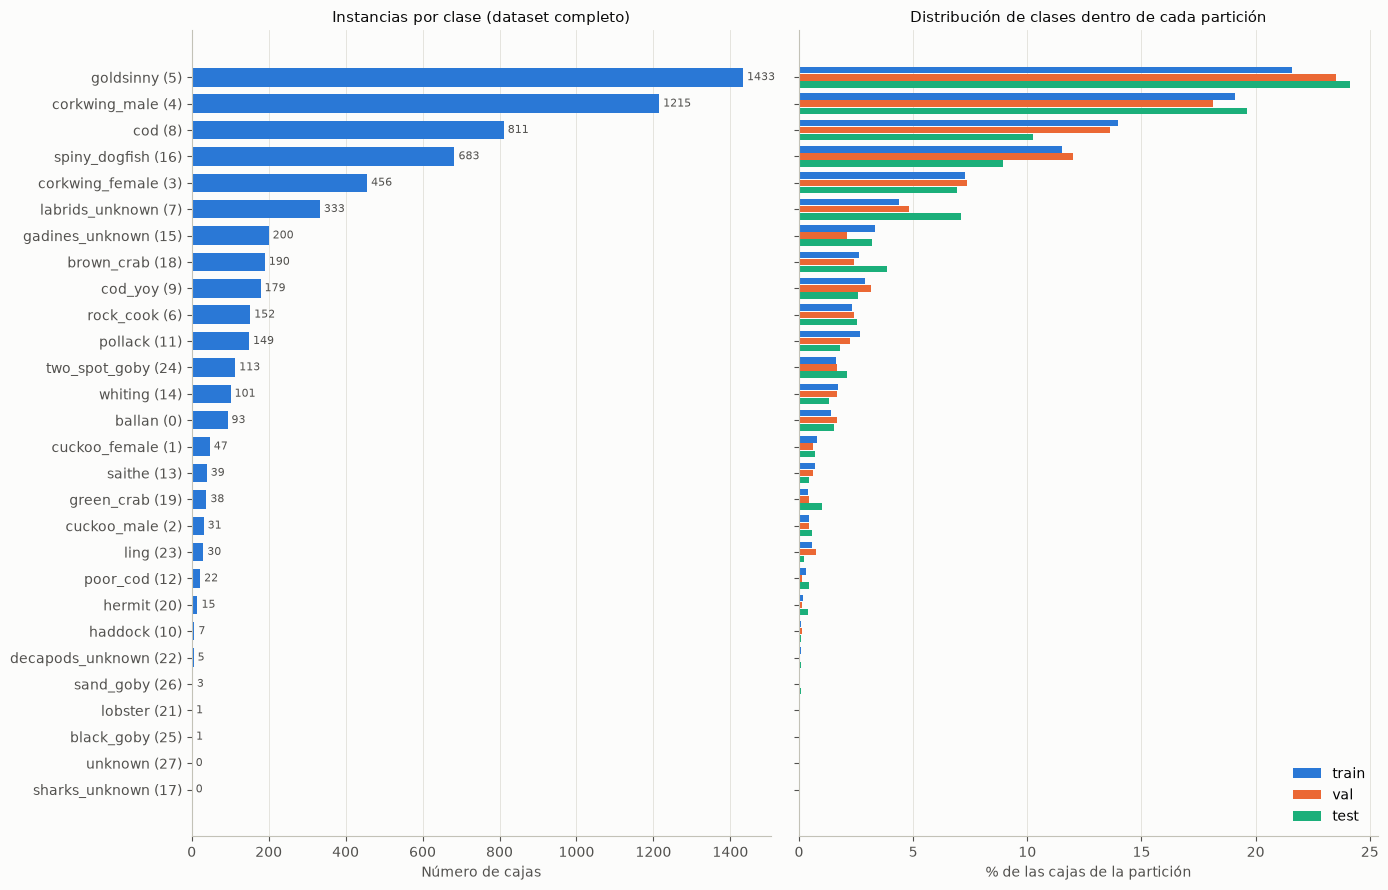

In [10]:
COLORES = {"train": AZUL, "val": NARANJA, "test": AQUA}
orden = instancias.sort_values(["total", "clase"]).index          # de menor a mayor: la más frecuente queda arriba
y = np.arange(NC)
etiquetas_y = [f"{NOMBRES[i]} ({i})" for i in orden]

fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)
ax = axes[0]
ax.barh(y, instancias.loc[orden, "total"], height=0.7, color=AZUL)
for yi, v in zip(y, instancias.loc[orden, "total"]):
    ax.text(v, yi, f" {v}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, etiquetas_y)
ax.set_title("Instancias por clase (dataset completo)")
ax.set_xlabel("Número de cajas")
ax.grid(axis="y", visible=False)

ax = axes[1]
porcentaje = instancias[["train", "val", "test"]] / instancias[["train", "val", "test"]].sum() * 100
alto_barra = 0.27
for s, desplazamiento in (("train", alto_barra), ("val", 0), ("test", -alto_barra)):
    ax.barh(y + desplazamiento, porcentaje.loc[orden, s], height=alto_barra * 0.9, color=COLORES[s], label=s)
ax.set_title("Distribución de clases dentro de cada partición")
ax.set_xlabel("% de las cajas de la partición")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

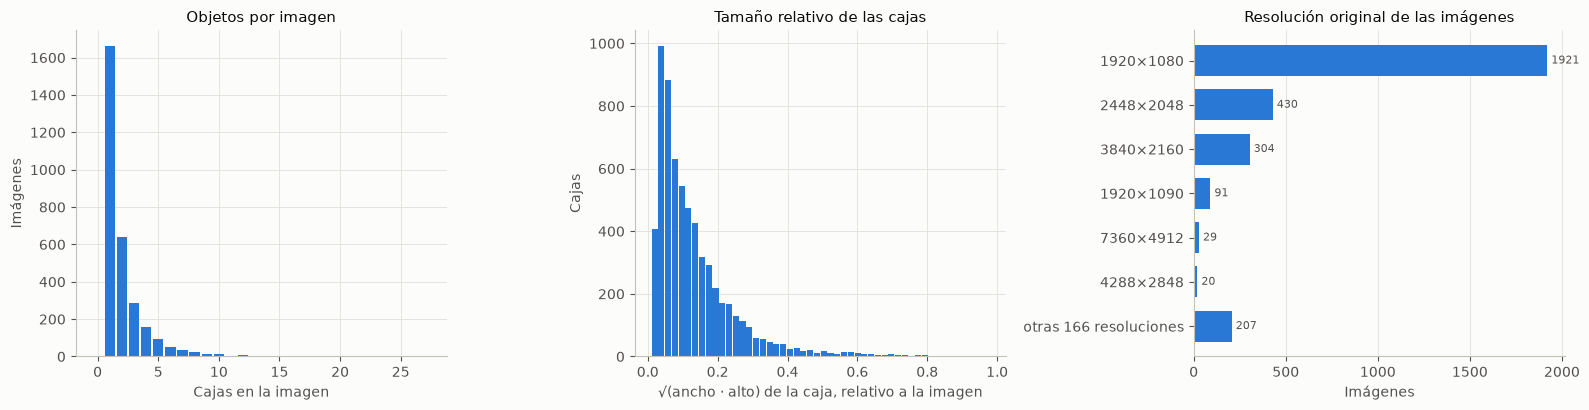

    count   mean    std    min    10%    50%    90%    max
w  6347.0  0.142  0.138  0.006  0.032  0.096  0.307  0.959
h  6347.0  0.135  0.127  0.009  0.031  0.094  0.291  1.000


In [11]:
cajas_wh = pd.DataFrame([(w, h) for cs in df.cajas for *_, w, h in cs], columns=["w", "h"])
resoluciones = (df.ancho.astype(str) + "×" + df.alto.astype(str)).value_counts()
top_res = pd.concat([resoluciones.head(6), pd.Series({f"otras {len(resoluciones) - 6} resoluciones": resoluciones.iloc[6:].sum()})])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
ax.hist(df.n_cajas, bins=np.arange(0, df.n_cajas.max() + 2) - 0.5, color=AZUL, rwidth=0.85)
ax.set_title("Objetos por imagen")
ax.set_xlabel("Cajas en la imagen")
ax.set_ylabel("Imágenes")

ax = axes[1]
ax.hist(np.sqrt(cajas_wh.w * cajas_wh.h), bins=50, color=AZUL, rwidth=0.9)
ax.set_title("Tamaño relativo de las cajas")
ax.set_xlabel("√(ancho · alto) de la caja, relativo a la imagen")
ax.set_ylabel("Cajas")

ax = axes[2]
ax.barh(top_res.index[::-1], top_res.values[::-1], height=0.7, color=AZUL)
for yi, v in enumerate(top_res.values[::-1]):
    ax.text(v, yi, f" {v}", va="center", fontsize=8, color="#52514e")
ax.set_title("Resolución original de las imágenes")
ax.set_xlabel("Imágenes")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "cajas_y_resoluciones.png", dpi=150, bbox_inches="tight")
plt.show()

print(cajas_wh.describe(percentiles=[0.1, 0.5, 0.9]).round(3).T)

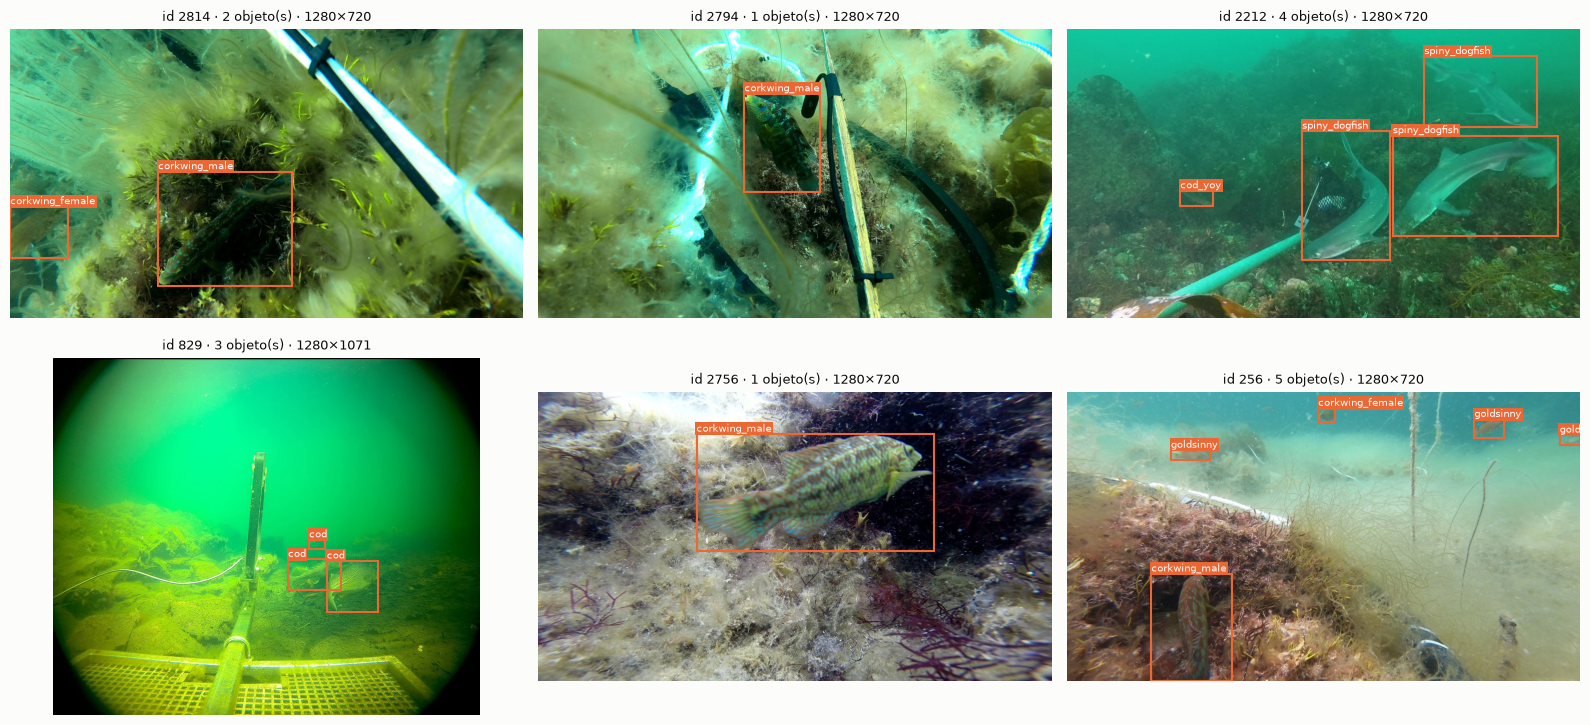

In [12]:
# Ejemplos del dataset exportado con sus cajas (sirve para comprobar que la exportación es correcta)
muestra = df[df.split == "train"].sample(6, random_state=SEMILLA)
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, fila in zip(axes.flat, muestra.itertuples()):
    img = Image.open(DIR_DATASET / "images" / fila.split / f"{fila.id}.jpg")
    W, H = img.size
    ax.imshow(img)
    for c, x, y, w, h in fila.cajas:
        x1, y1 = (x - w / 2) * W, (y - h / 2) * H
        ax.add_patch(plt.Rectangle((x1, y1), w * W, h * H, fill=False, ec=NARANJA, lw=1.5))
        ax.text(x1, y1, NOMBRES[c], color="white", fontsize=7, va="top" if y1 < 0.05 * H else "bottom",
                bbox=dict(fc=NARANJA, ec="none", pad=1), clip_on=True)
    ax.set_title(f"id {fila.id} · {fila.n_cajas} objeto(s) · {W}×{H}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "ejemplos_train.png", dpi=120, bbox_inches="tight")
plt.show()

## Resumen

- Particiones en `splits/` (compartir con el grupo junto con la **huella** impresa en la sección 4).
- Dataset en `datasets/fjordfish/` con `fjordfish.yaml` (formato YOLO). La CNN propia puede leer las mismas carpetas `images/<split>` y `labels/<split>`.
- Figuras del análisis exploratorio en `resultados/dataset/`.

> ✍️ *Observaciones del análisis exploratorio y decisiones sobre las clases (desbalance, clases sin instancias o muy raras, tamaño de los objetos): completar por el grupo.*

## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).